# FPS, задержка и память моделей

Сравнение включённых моделей через общий `Predictor`: CPU/CUDA, batch=1,
прогрев и отдельные процессы. [Подробный протокол и варианты измерений](FPS_MEASUREMENT.md).
Синтетический поток не подтверждает качество реального видео. Полный конвейер
защиты растений и HSV здесь не измеряется. Загрузка весов и обучение не запускаются.


In [1]:
from pathlib import Path
import sys

# Поддерживаются запуск из корня репозитория и из manual_notebooks.
NOTEBOOK_DIR = Path.cwd() if (Path.cwd() / "scripts" / "common.py").is_file() else Path.cwd() / "manual_notebooks"
if not (NOTEBOOK_DIR / "scripts" / "common.py").is_file():
    raise RuntimeError("Open this notebook from the repository root or manual_notebooks")
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

from scripts import common as cmn
from scripts.workflows import enabled_specs
from scripts.benchmark import BenchmarkConfig, run_benchmarks
from scripts.benchmark_plots import summary_table, plot_benchmarks, plot_fps_over_time, plot_latency_over_time


## Конфигурация

`cmn.MODELS` остаётся единственным источником выбора. Для изменения набора задайте,
например, `cmn.MODELS["rf-detr-m"] = False` перед созданием `CHECKPOINTS`.
Для воспроизводимого сравнения замените пути удобных копий на веса конкретных запусков.
Изображения читаются до измерения, затем циклически используются в заданном порядке.


In [2]:
# Измените настройки перед запуском. Недоступные файлы вызывают явную ошибку.
CHECKPOINTS = {
    spec.id: cmn.TRAINED_WEIGHTS_DIR / f"{spec.id}.pt"
    for spec in enabled_specs()
}
IMAGE_PATHS = [cmn.DATASET_PATH / "images" / "image_000646.png"]
DEVICES = ["cpu"]  # Например: ["cpu", "cuda:0"].
PREDICTION_OPTIONS = {
    spec.id: ({"imgsz": 640, "conf": 0.25, "rect": True}
              if spec.backend == "ultralytics" else {"conf": 0.25})
    for spec in enabled_specs()
}
# RF-DETR использует разрешение checkpoint; несовместимый imgsz вызовет ошибку.
PROMPTS = {}  # JSON-совместимые подсказки для моделей, которым они нужны.
RUN_NOTES = ""  # Оборудование, режим питания, внешние ограничения.

WARMUP_FRAMES = 30
MEASUREMENT_SECONDS = 30
REPETITIONS = 1
INPUT_RATES = (10, 20, 30, 60, 300)
ORDER_SEED = 20261028
MEMORY_INTERVAL_SECONDS = 0.01
OUTPUT_ROOT = cmn.ROOT / "experiments" / "benchmarks"

for spec in enabled_specs():
    print(spec.id, spec.backend, CHECKPOINTS[spec.id], spec.unavailable_reason("predict") or "Ready for preflight")


yolov8n ultralytics /home/natsusa/academic/tobacco-article/weights/trained/yolov8n.pt Ready for preflight
yolo26n ultralytics /home/natsusa/academic/tobacco-article/weights/trained/yolo26n.pt Ready for preflight
rf-detr-m rfdetr /home/natsusa/academic/tobacco-article/weights/trained/rf-detr-m.pt Ready for preflight


## Прямое измерение

Запустите следующую ячейку, когда нужно измерить direct inference.
Поток запускается собственной ячейкой ниже. Флагов включения нет.
Длительность direct: `MEASUREMENT_SECONDS × REPETITIONS` на пару модель/устройство
плюс загрузка и прогрев. Для smoke test: 2 кадра прогрева, 1 секунда, 1 повтор.

Прогрев повторяется перед каждым окном с теми же параметрами. Каждый завершённый
повтор сразу сохраняется вместе с задержками, памятью и окружением.
Путь к каталогу и worker.log выводится до начала работы.


In [3]:
config = BenchmarkConfig(
    warmup_frames=WARMUP_FRAMES, duration_s=MEASUREMENT_SECONDS,
    repetitions=REPETITIONS, input_rates=INPUT_RATES,
    direct=True, stream=False,
    seed=ORDER_SEED, memory_interval_s=MEMORY_INTERVAL_SECONDS,
)
DIRECT_RESULT_DIRECTORY = run_benchmarks(
    CHECKPOINTS, IMAGE_PATHS, devices=DEVICES, config=config,
    prediction_options=PREDICTION_OPTIONS, prompts=PROMPTS,
    output_root=OUTPUT_ROOT, notes=RUN_NOTES,
)
RESULT_DIRECTORY = DIRECT_RESULT_DIRECTORY
print(f"Completed: {RESULT_DIRECTORY}")


Benchmark directory: /home/natsusa/academic/tobacco-article/experiments/benchmarks/20261121T084330Z-54a6e1f5
Running yolov8n on cpu; log: /home/natsusa/academic/tobacco-article/experiments/benchmarks/20261121T084330Z-54a6e1f5/yolov8n-cpu/worker.log
Running yolo26n on cpu; log: /home/natsusa/academic/tobacco-article/experiments/benchmarks/20261121T084330Z-54a6e1f5/yolo26n-cpu/worker.log
Running rf-detr-m on cpu; log: /home/natsusa/academic/tobacco-article/experiments/benchmarks/20261121T084330Z-54a6e1f5/rf-detr-m-cpu/worker.log
Completed: /home/natsusa/academic/tobacco-article/experiments/benchmarks/20261121T084330Z-54a6e1f5


## Синтетический поток

Запустите эту ячейку для sweep по `INPUT_RATES`; direct-ячейку запускать не обязательно.
Длительность: `MEASUREMENT_SECONDS × REPETITIONS × len(INPUT_RATES)` на пару
модель/устройство плюс загрузка и прогрев. При запуске всех ячеек выполняются оба режима.


In [4]:
config = BenchmarkConfig(
    warmup_frames=WARMUP_FRAMES, duration_s=MEASUREMENT_SECONDS,
    repetitions=REPETITIONS, input_rates=INPUT_RATES,
    direct=False, stream=True,
    seed=ORDER_SEED, memory_interval_s=MEMORY_INTERVAL_SECONDS,
)
STREAM_RESULT_DIRECTORY = run_benchmarks(
    CHECKPOINTS, IMAGE_PATHS, devices=DEVICES, config=config,
    prediction_options=PREDICTION_OPTIONS, prompts=PROMPTS,
    output_root=OUTPUT_ROOT, notes=RUN_NOTES,
)
RESULT_DIRECTORY = STREAM_RESULT_DIRECTORY
print(f"Completed: {RESULT_DIRECTORY}")


Benchmark directory: /home/natsusa/academic/tobacco-article/experiments/benchmarks/20261121T084534Z-ceb84974
Running yolov8n on cpu; log: /home/natsusa/academic/tobacco-article/experiments/benchmarks/20261121T084534Z-ceb84974/yolov8n-cpu/worker.log
Running yolo26n on cpu; log: /home/natsusa/academic/tobacco-article/experiments/benchmarks/20261121T084534Z-ceb84974/yolo26n-cpu/worker.log
Running rf-detr-m on cpu; log: /home/natsusa/academic/tobacco-article/experiments/benchmarks/20261121T084534Z-ceb84974/rf-detr-m-cpu/worker.log
Completed: /home/natsusa/academic/tobacco-article/experiments/benchmarks/20261121T084534Z-ceb84974


## Таблица и графики без повторного inference

Задайте `SAVED_RESULT_DIRECTORY`, чтобы открыть прошлый или прерванный запуск.
По умолчанию отображается последний выполненный режим. Можно указать
`DIRECT_RESULT_DIRECTORY` или `STREAM_RESULT_DIRECTORY` для выбора режима.
Processing FPS — число завершённых кадров / фактическая длительность окна.
Frame latency включает копирование и очередь, поэтому её обратная величина не FPS.

RSS — память всего worker, выборочный пик с интервалом 10 мс. CUDA allocated/reserved —
отдельные показатели аллокатора PyTorch после прогрева, не полная VRAM устройства.
Их нельзя складывать с RAM или друг с другом. На CPU CUDA-поля отсутствуют (`null`).
Интервалы на графиках — min/max по повторам, не доверительные интервалы.


,model_id,device,mode,input_fps,repetition,processed,elapsed_s,processing_fps,prediction_ms_mean,prediction_ms_median,...,dropped,generation_fps,drop_rate,rss_warm_mib,rss_sampled_peak_mib,cuda_allocated_mib_warm,cuda_reserved_mib_warm,cuda_allocated_mib_peak,cuda_reserved_mib_peak,rss_baseline_mib
0,rf-detr-m,cpu,stream,20,1,47,30.160427,1.558333,641.683612,641.934342,...,556,20.026242,18.434752,1271.101562,1273.484375,NaN,NaN,NaN,NaN,568.488281
1,rf-detr-m,cpu,stream,60,1,47,30.097649,1.561584,640.353012,637.312359,...,1758,60.004686,58.409877,1274.640625,1274.714844,NaN,NaN,NaN,NaN,568.488281
2,rf-detr-m,cpu,stream,30,1,46,30.356184,1.515342,659.894836,640.255013,...,864,30.010359,28.462075,1275.433594,1275.460938,NaN,NaN,NaN,NaN,568.488281
3,rf-detr-m,cpu,stream,10,1,48,30.243969,1.587093,630.060915,628.143377,...,254,10.018526,8.398369,1276.179688,1276.199219,NaN,NaN,NaN,NaN,568.488281
4,rf-detr-m,cpu,stream,300,1,46,30.072698,1.529627,653.734574,641.319811,...,8974,299.973088,298.410208,1276.953125,1276.968750,NaN,NaN,NaN,NaN,568.488281
5,yolo26n,cpu,stream,20,1,291,31.490465,9.240892,107.090228,48.363399,...,338,19.974300,10.733408,830.804688,846.937500,NaN,NaN,NaN,NaN,568.304688
6,yolo26n,cpu,stream,60,1,686,30.001429,22.865577,43.719851,43.041937,...,1114,60.030474,37.131564,833.585938,846.898438,NaN,NaN,NaN,NaN,568.304688
7,yolo26n,cpu,stream,30,1,588,30.039079,19.574501,51.071609,43.912647,...,313,30.027551,10.419760,836.867188,850.023438,NaN,NaN,NaN,NaN,568.304688
8,yolo26n,cpu,stream,10,1,275,30.066256,9.146467,74.629141,64.417131,...,26,10.011223,0.864757,839.890625,853.027344,NaN,NaN,NaN,NaN,568.304688
9,yolo26n,cpu,stream,300,1,647,30.025745,21.548175,46.395011,42.659245,...,8353,299.776080,278.194600,842.695312,858.933594,NaN,NaN,NaN,NaN,568.304688


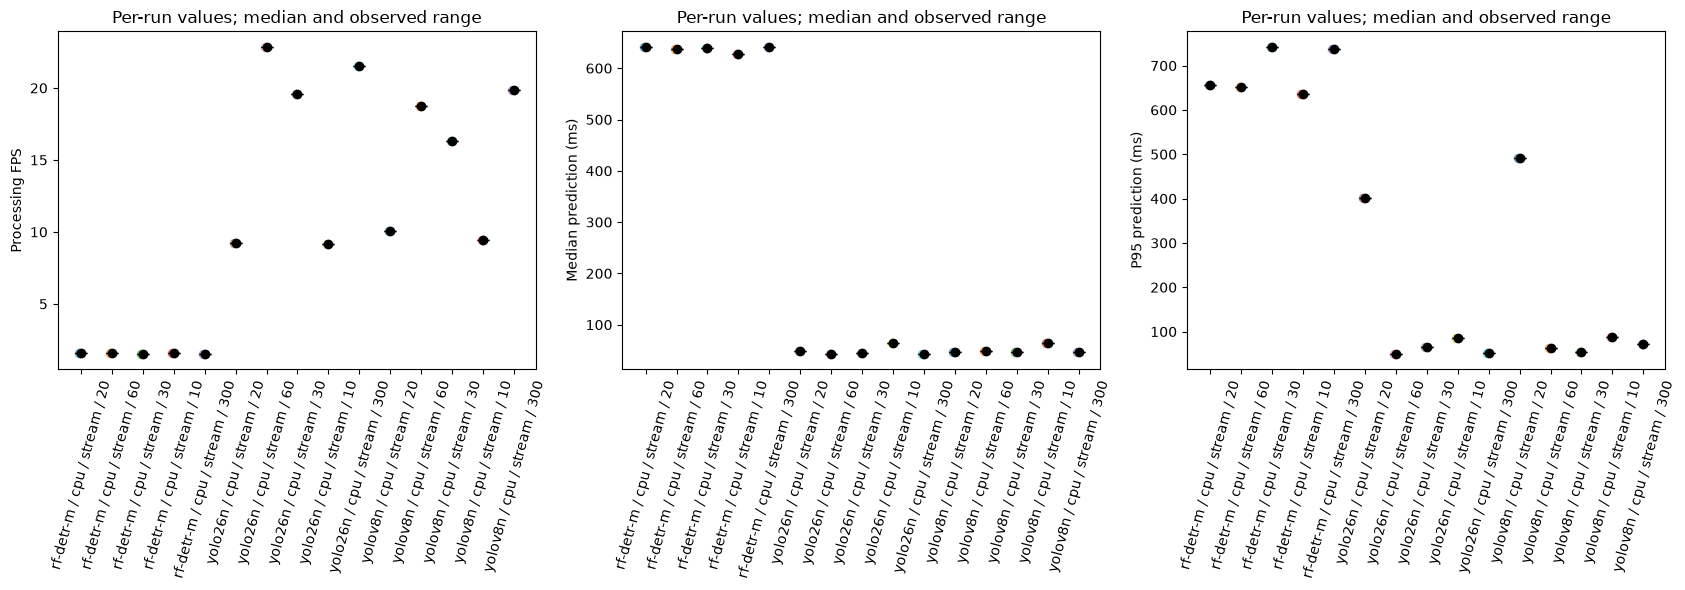

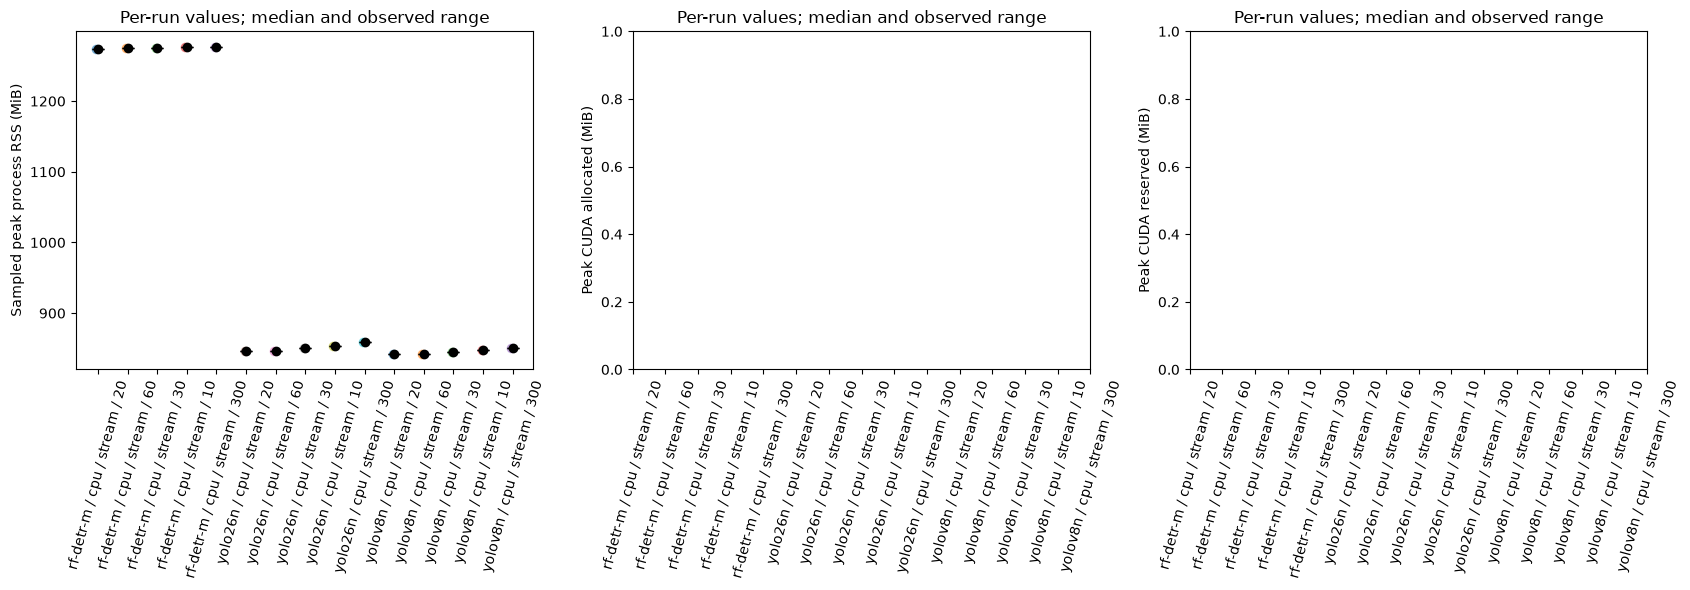

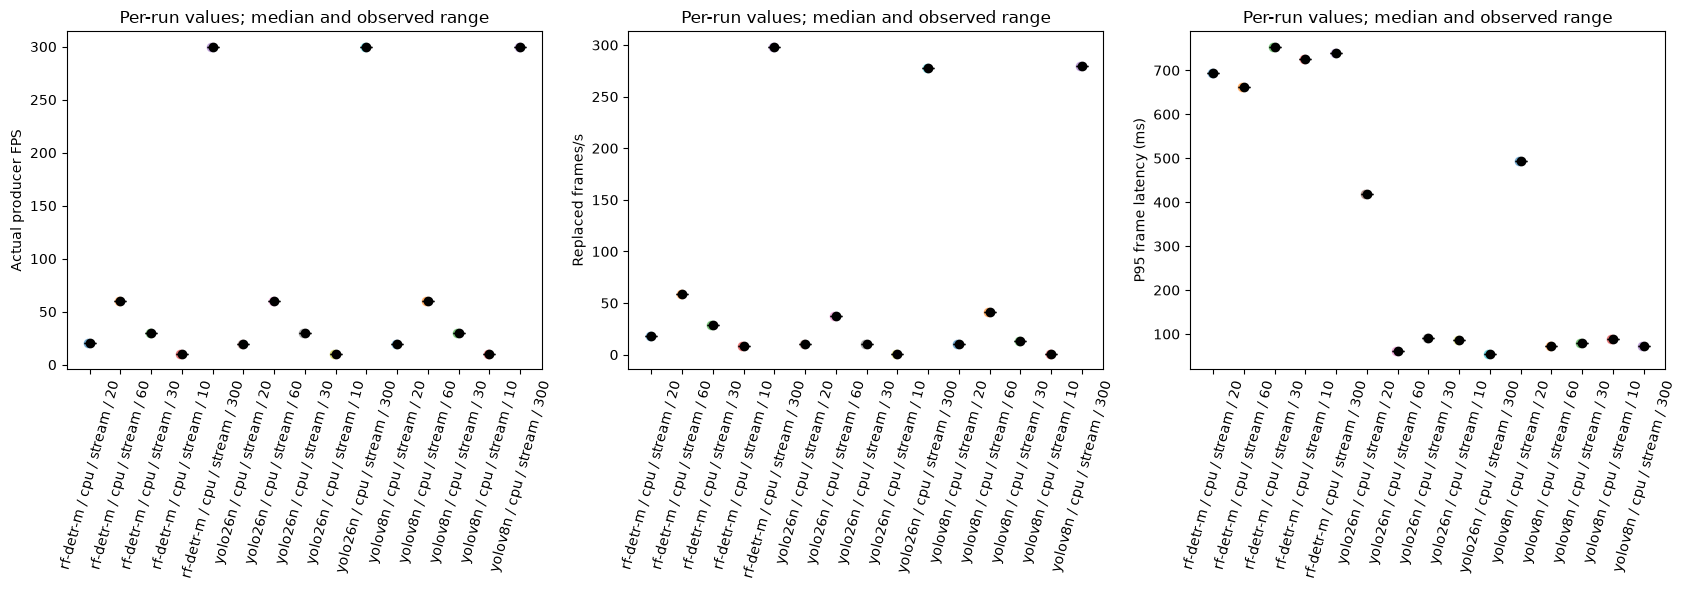

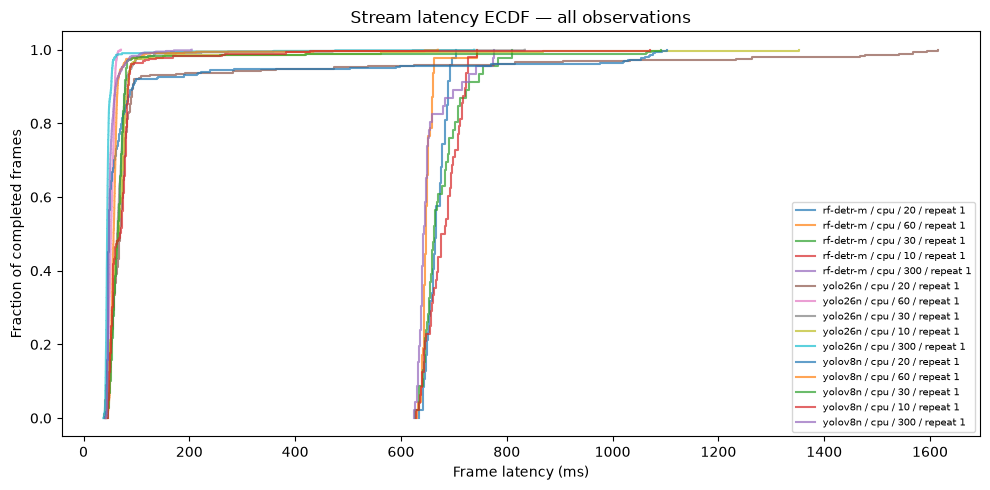

In [5]:
SAVED_RESULT_DIRECTORY = None  # Например: OUTPUT_ROOT / "20261121T120000Z-..."
results_path = SAVED_RESULT_DIRECTORY or globals().get("RESULT_DIRECTORY")
if results_path is not None:
    from IPython.display import display
    display(summary_table(results_path))
    plot_benchmarks(results_path)
else:
    print("Run the benchmark or set SAVED_RESULT_DIRECTORY to an existing results directory.")


## FPS во времени для каждой модели

Отдельная фигура для каждой пары модель/устройство, отдельная панель для каждого
режима/входной частоты. По X — секунды после прогрева, по Y — число завершённых
кадров в окне / длительность окна. Повторы показаны отдельными линиями.
Последнее неполное окно делится на его фактическую длительность, пустые окна дают 0 FPS.
Изменяйте `FPS_BIN_SECONDS` для более подробного или сглаженного отображения.
Эта ячейка читает сохранённые результаты и не запускает inference.


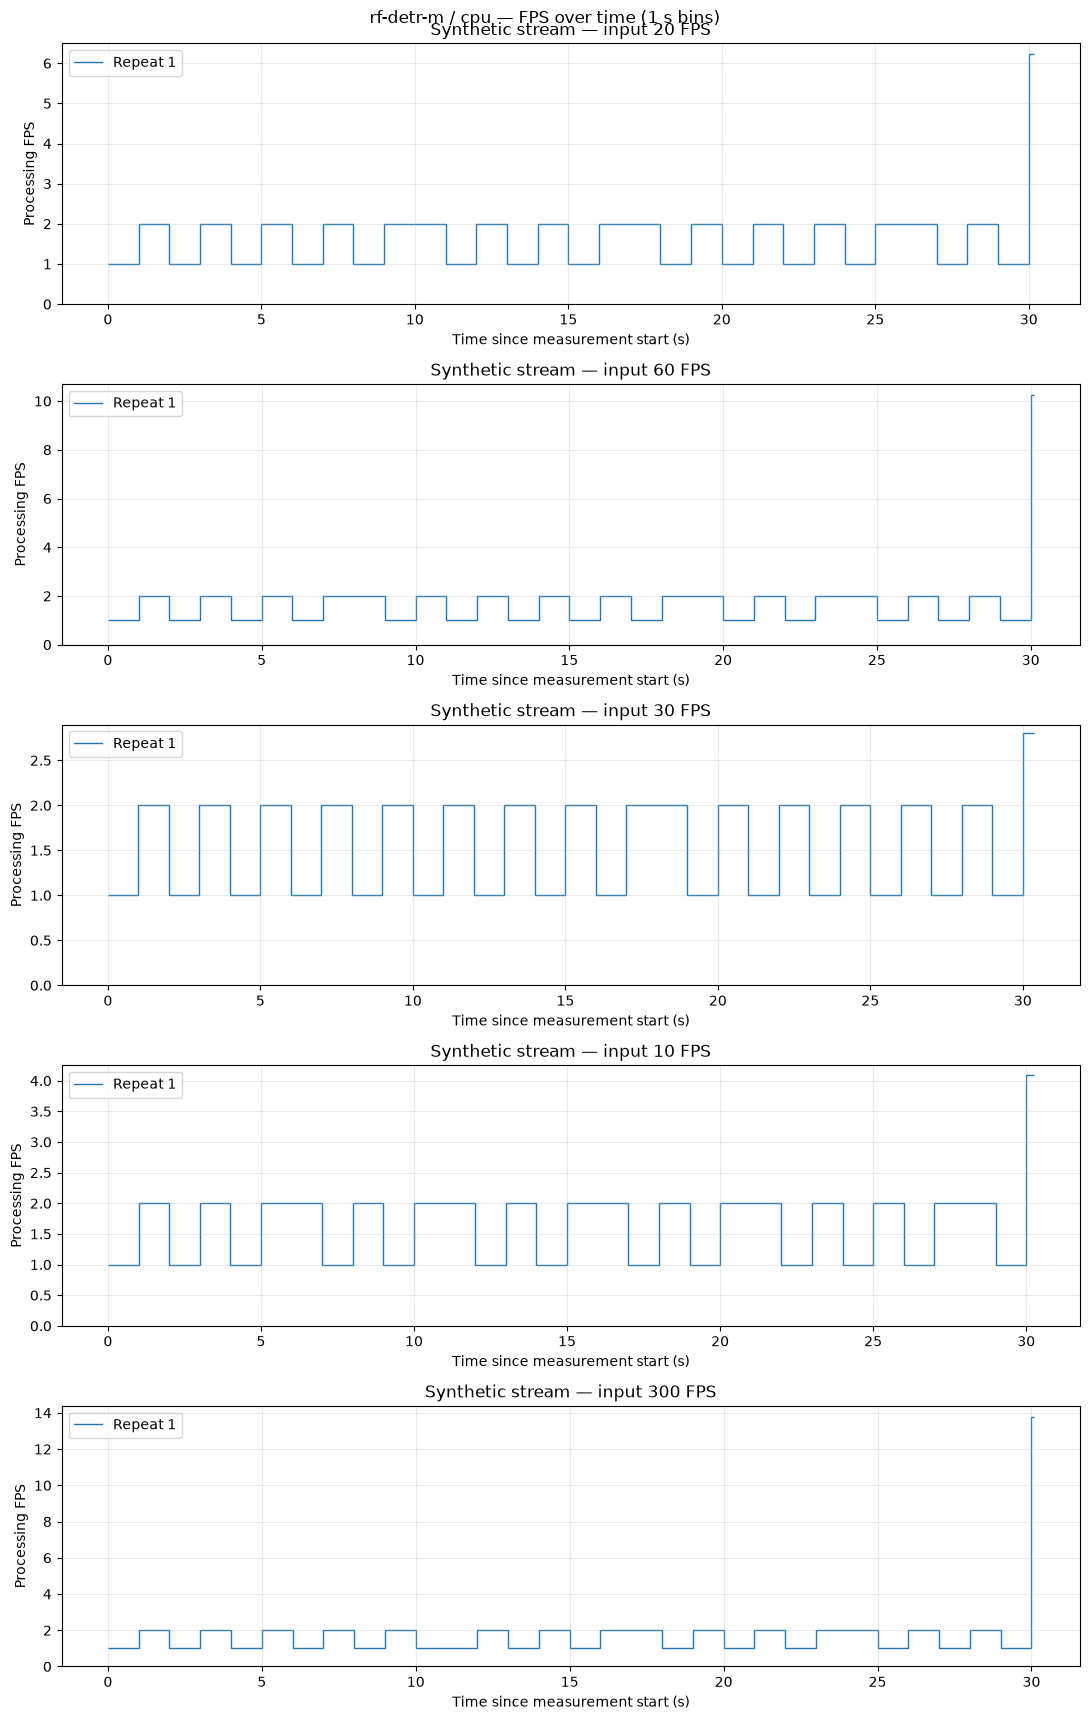

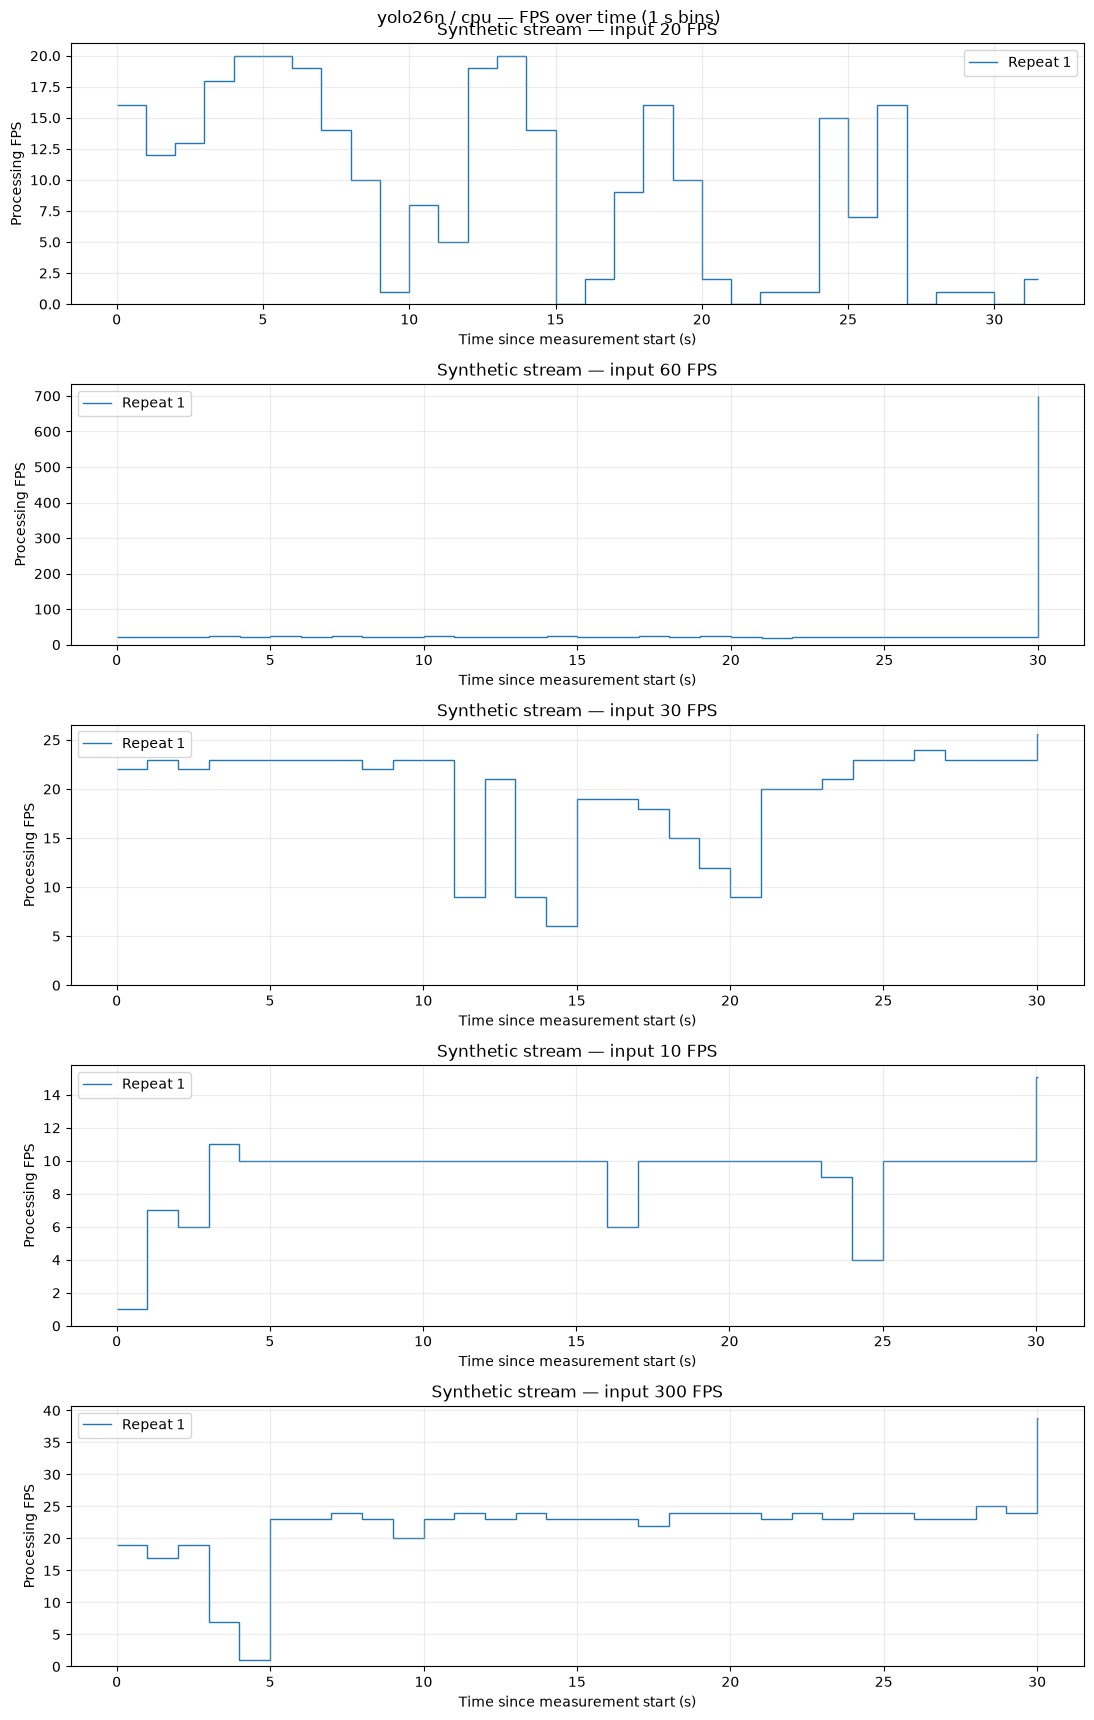

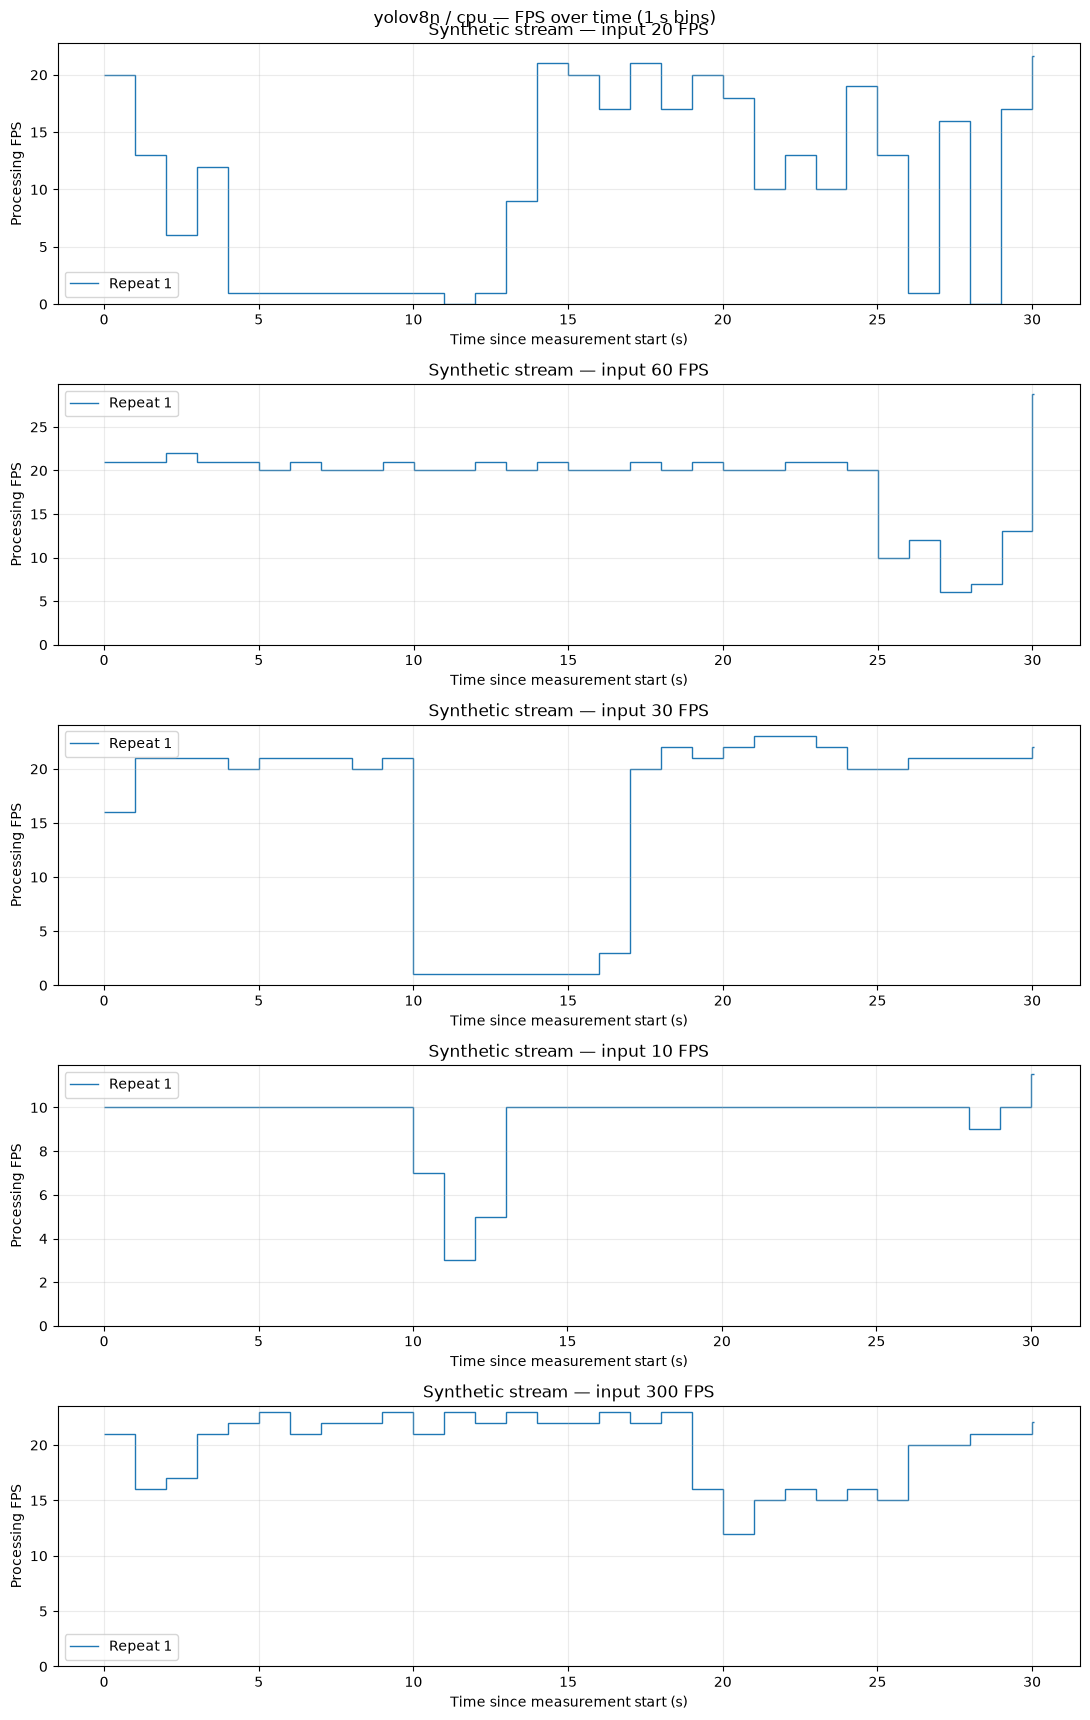

In [6]:
FPS_BIN_SECONDS = 1.0
if results_path is not None:
    plot_fps_over_time(results_path, bin_seconds=FPS_BIN_SECONDS)
else:
    print("Select a results directory in the table cell above.")


## Задержка (мс) во времени для каждой модели

По X — время завершения кадра в секундах после начала измерения, по Y — задержка
в миллисекундах. Сплошная линия — время предсказания; для синтетического потока
пунктиром дополнительно показана задержка кадра с копированием и очередью.
Каждый повтор показан отдельно. Все наблюдения сохранены, без фильтрации выбросов
и усреднения. Используются те же сохранённые результаты, что и для FPS.


In [ ]:
if results_path is not None:
    plot_latency_over_time(results_path)
else:
    print("Select a results directory in the table cell above.")
